# Fields of a sphere in a plane wave

This notebook computes the fields near a sphere in a plane wave: the electric and the magnetic fields in optics, and the pressure and the velocity in acoustics.
The fields are the Mie series with the coefficients $a_j$, $b_j$, $c_j$ and $d_j$ from `mielib`:
in the complex vector spherical harmonics in optics, and in the Legendre polynomials in acoustics.
The [theory note](https://github.com/toftul/mielib/blob/main/docs/theory/mielib_theory.pdf) gives them in the sections
"Plane waves", "Electromagnetic Mie problem" and "Acoustic Mie problem".
The fields are normalized as $\sqrt{\varepsilon}\mathbf{E}/\mathcal{A}$ and $\sqrt{\mu}\mathbf{H}/\mathcal{A}$ in optics and as $\sqrt{\beta}\,p/\mathcal{A}$ and $\sqrt{\rho}\,\mathbf{v}/\mathcal{A}$ in acoustics,
with the parameters of the medium at the point and the amplitude $\mathcal{A}$ of the incident wave.
The positions are in units of the radius $a$.
The figures use the style file `phys-plots.mplstyle` and the helpers in `figure_style.py`, which are next to this notebook.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.special as sp

from mielib import acoustics, coordinates, optics, special, vsh
from figure_style import use_paper_style, figure, letter, edges, signed_map

use_paper_style();

## Optics

A lossless sphere with the permittivity $\varepsilon_{\rm rel} = 12$ and the permeability $\mu_{\rm rel} = 4$ relative to the host.
The size parameter is at the maximum of the magnetic dipole scattering, row $j = 1$ of `q.sca_m`.

In [2]:
eps_rel, mu_rel = 12, 4

a = 1
k = np.linspace(0.01, 1, 2000)
q = optics.cross_sections(k, a, eps_rel, mu_rel)

ka = k[np.argmax(q.sca_m[1])] * a
print(f'ka = {ka:.3f}')

ka = 0.522


The incident wave is $\sqrt{\varepsilon}\mathbf{E} = \mathcal{A}\hat{\mathbf{x}}\, e^{ikz}$ and $\sqrt{\mu}\mathbf{H} = \mathcal{A}\hat{\mathbf{y}}\, e^{ikz}$.
The normalized fields $\mathbf{e} = \sqrt{\varepsilon}\mathbf{E}/\mathcal{A}$ and $\mathbf{h} = \sqrt{\mu}\mathbf{H}/\mathcal{A}$,
with $\varepsilon$ and $\mu$ of the medium at the point, are
$$
\mathbf{e} = \sum_{jm}\left(A_{jm}\mathbf{N}_{jm} + B_{jm}\mathbf{M}_{jm}\right), \qquad
\mathbf{h} = -i\sum_{jm}\left(B_{jm}\mathbf{N}_{jm} + A_{jm}\mathbf{M}_{jm}\right),
$$
with the complex harmonics `vsh.N` and `vsh.M`.
The incident wave has $z_j = j_j(kr)$ and only $m = \pm 1$:
$A_{\pm1, j} = \pm\eta_j/2$ and $B_{\pm1, j} = \eta_j/2$ with $\eta_j = i^{j+1}\sqrt{4\pi(2j+1)/[j(j+1)]}$.
The scattered field has $z_j = h^{(1)}_j(kr)$, and the internal field has $z_j = j_j(k_p r)$ with $k_p = k\sqrt{\varepsilon_{\rm rel}\mu_{\rm rel}}$.
Their amplitudes are
$$
A^{\rm sc}_{jm} = -a_j A_{jm}, \qquad B^{\rm sc}_{jm} = -b_j B_{jm}, \qquad
A^{\rm in}_{jm} = \sqrt{\varepsilon_{\rm rel}}\, d_j A_{jm}, \qquad B^{\rm in}_{jm} = \sqrt{\varepsilon_{\rm rel}}\, c_j B_{jm},
$$
with the coefficients of Bohren & Huffman from `optics.mie_a`, `optics.mie_b`, `optics.mie_c` and `optics.mie_d`.
The factor $\sqrt{\varepsilon_{\rm rel}}$ is there because Bohren & Huffman normalize $c_j$ and $d_j$ to the internal $\mathbf{E}$.

In [3]:
def eh(j, rho, theta, phi, alpha, beta, superscript):
    # the terms j, m = ±1 of e = Σ (A N + B M) and h = -i Σ (B N + A M) with A_mj = alpha m η_j/2 and B_mj = beta η_j/2
    eta = 1j**(j + 1) * np.sqrt(4 * np.pi * (2 * j + 1) / (j * (j + 1)))
    e, h = 0, 0
    for m in (1, -1):
        A, B = alpha * m * eta / 2, beta * eta / 2
        N = vsh.N(j, m, rho, theta, phi, superscript=superscript)
        M = vsh.M(j, m, rho, theta, phi, superscript=superscript)
        e = e + A * N + B * M
        h = h - 1j * (B * N + A * M)
    return e, h


def optical_fields(x, y, z, ka, eps_rel, mu_rel, jmax):
    # e = √ε E/𝒜 and h = √μ H/𝒜 in Cartesian components at the points (x, y, z) in units of a
    x, y, z = np.broadcast_arrays(x, y, z)
    r, theta, phi = coordinates.cart2sph(x, y, z)
    out, ins = r >= 1, r < 1
    sqrt_eps = np.sqrt(eps_rel + 0j)
    kpa = sqrt_eps * np.sqrt(mu_rel + 0j) * ka

    e = np.zeros((3,) + r.shape, dtype=complex)
    h = np.zeros((3,) + r.shape, dtype=complex)
    for j in range(1, jmax + 1):
        a_j, b_j, c_j, d_j = (f(j, ka, eps_rel, mu_rel) for f in [optics.mie_a, optics.mie_b, optics.mie_c, optics.mie_d])
        e_inc, h_inc = eh(j, ka * r[out], theta[out], phi[out], 1, 1, superscript=1)
        e_sc, h_sc = eh(j, ka * r[out], theta[out], phi[out], -a_j, -b_j, superscript=3)
        e_in, h_in = eh(j, kpa * r[ins], theta[ins], phi[ins], sqrt_eps * d_j, sqrt_eps * c_j, superscript=1)
        e[:, out] += e_inc + e_sc
        h[:, out] += h_inc + h_sc
        e[:, ins] += e_in
        h[:, ins] += h_in

    return coordinates.vector_sph2cart(e, theta, phi), coordinates.vector_sph2cart(h, theta, phi)

All the sums stop at one $j_{\max}$.
The incident series converges only for $kr$ below about $j_{\max}$, so $j_{\max}$ is `special.wiscombe_jmax` at the corners of the plot, $r = 3\sqrt{2}\,a$.

**Checks.** (1) Without the sphere, $\varepsilon_{\rm rel} = \mu_{\rm rel} = 1$, so $a_j = b_j = 0$ and $c_j = d_j = 1$, and the sums must give the incident wave everywhere in the plot.
(2) The tangential components of $\mathbf{E} \propto \mathbf{e}/\sqrt{\varepsilon}$ and $\mathbf{H} \propto \mathbf{h}/\sqrt{\mu}$
and the normal components of $\varepsilon\mathbf{E} \propto \sqrt{\varepsilon}\,\mathbf{e}$ and $\mu\mathbf{H} \propto \sqrt{\mu}\,\mathbf{h}$ are continuous at $r = a$.

In [4]:
jmax = special.wiscombe_jmax(ka * 3 * np.sqrt(2))
print(f'jmax = {jmax}')

X, Z = np.meshgrid(np.linspace(-3, 3, 61), np.linspace(-3, 3, 61))
e, h = optical_fields(X, 0, Z, ka, 1, 1, jmax)
wave, zero = np.exp(1j * ka * Z), np.zeros(Z.shape)
print('without the sphere, the largest error in')
print(f'  e:  {np.max(np.abs(e - [wave, zero, zero])):.1e}')
print(f'  h:  {np.max(np.abs(h - [zero, wave, zero])):.1e}')

theta, phi = np.meshgrid(np.linspace(0.1, 3.0, 7), np.linspace(0.2, 6.0, 7))
sides = []
for r in [1 - 1e-12, 1 + 1e-12]:
    e, h = optical_fields(*coordinates.sph2cart(r, theta, phi), ka, eps_rel, mu_rel, jmax)
    sides.append((coordinates.vector_cart2sph(e, theta, phi), coordinates.vector_cart2sph(h, theta, phi)))
(e_in, h_in), (e_out, h_out) = sides
sqrt_eps, sqrt_mu = np.sqrt(eps_rel + 0j), np.sqrt(mu_rel + 0j)

print('at r = a, the largest jump in')
print(f'  tangential E:  {np.max(np.abs(e_in[1:] / sqrt_eps - e_out[1:])):.1e}')
print(f'  tangential H:  {np.max(np.abs(h_in[1:] / sqrt_mu - h_out[1:])):.1e}')
print(f'  normal eps E:  {np.max(np.abs(sqrt_eps * e_in[0] - e_out[0])):.1e}')
print(f'  normal mu H:   {np.max(np.abs(sqrt_mu * h_in[0] - h_out[0])):.1e}')

jmax = 9


without the sphere, the largest error in
  e:  4.8e-06
  h:  8.6e-07
at r = a, the largest jump in
  tangential E:  4.0e-11
  tangential H:  1.3e-11
  normal eps E:  3.7e-11
  normal mu H:   1.8e-10


**Figure 1.** The fields at the magnetic dipole resonance.
(A) The electric field $|\mathbf{e}| = |\sqrt{\varepsilon}\mathbf{E}|/\mathcal{A}$ in the plane $y = 0$.
(B) The magnetic field $|\mathbf{h}| = |\sqrt{\mu}\mathbf{H}|/\mathcal{A}$ in the plane $x = 0$.
The incident $\mathbf{E}$ is along $x$, and the mirror symmetries of the problem keep $\mathbf{E}$ in the plane $y = 0$ and $\mathbf{H}$ in the plane $x = 0$.
The lines show the instantaneous fields $\mathrm{Re}[\mathbf{e}\, e^{-i\omega t}]$ and $\mathrm{Re}[\mathbf{h}\, e^{-i\omega t}]$ at $\omega t = \pi/4$.
The dashed circle is the surface of the sphere.
The electric field circulates in a loop inside the sphere, and the magnetic field goes through the loop along $y$, as for a magnetic dipole along $y$.
Inside the sphere, $|\mathbf{e}|$ reaches 47 on the loop, and $|\mathbf{h}| \approx 68$ at the centre.

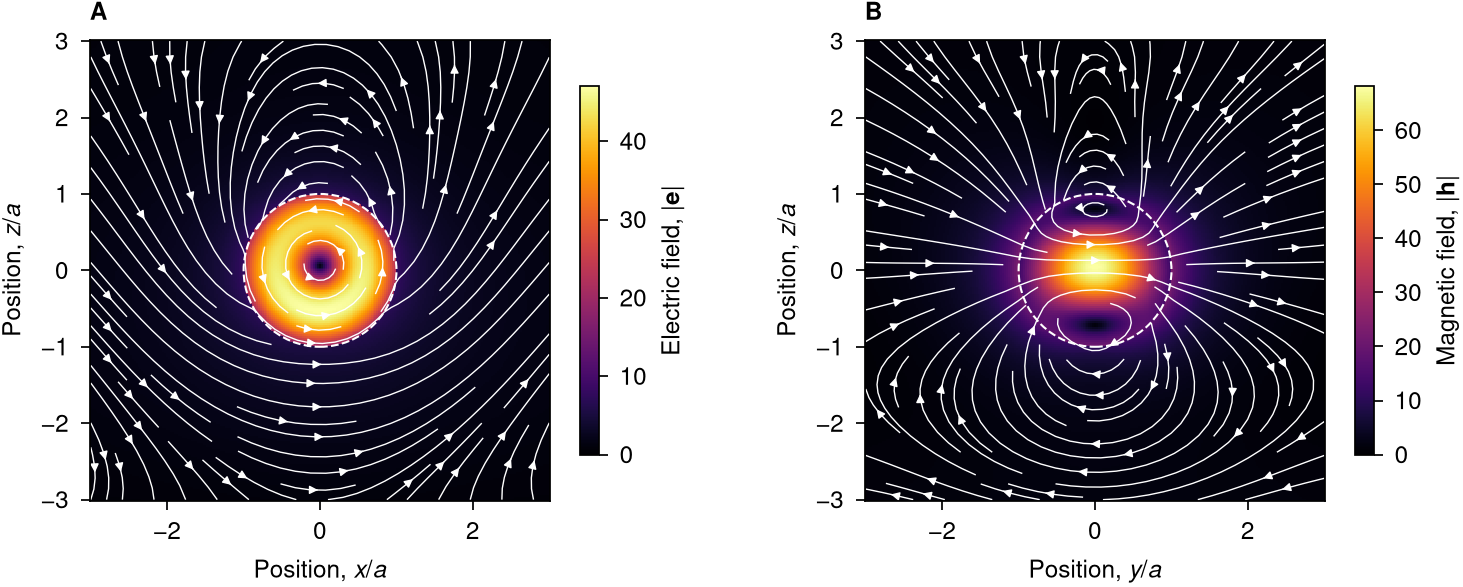

In [5]:
u = np.linspace(-3, 3, 241)                     # position in units of a
U, V = np.meshgrid(u, u)
e, _ = optical_fields(U, 0, V, ka, eps_rel, mu_rel, jmax)
_, h = optical_fields(0, U, V, ka, eps_rel, mu_rel, jmax)
wt = np.pi / 4


def vector_map(ax, u, F, i, wt, label):
    # |F| and the lines of Re[F exp(-iωt)] in a plane; F[i] is along the horizontal axis and F[2] along z
    magnitude = np.sqrt(np.sum(np.abs(F)**2, axis=0))
    mesh = ax.pcolormesh(edges(u), edges(u), magnitude, vmin=0, shading='flat', rasterized=True)
    snapshot = np.real(F * np.exp(-1j * wt))
    ax.streamplot(u, u, snapshot[i], snapshot[2], color='w', linewidth=0.4, arrowsize=0.5)
    bar = ax.figure.colorbar(mesh, ax=ax, shrink=0.8, label=label)
    bar.outline.set_linewidth(0.5)


fig, (ax1, ax2) = figure('double', cols=2)
vector_map(ax1, u, e, 0, wt, r'Electric field, $|\mathbf{e}|$')
vector_map(ax2, u, h, 1, wt, r'Magnetic field, $|\mathbf{h}|$')

for ax, horizontal, name in zip([ax1, ax2], 'xy', 'AB'):
    ax.add_patch(plt.Circle((0, 0), 1, fill=False, color='w', ls='--', lw=0.6))
    ax.set_aspect('equal')
    ax.set_xlabel(rf'Position, ${horizontal}/a$')
    ax.set_ylabel(r'Position, $z/a$')
    letter(ax, name)

plt.show()

## Acoustics

The fluid sphere of `cross_sections.ipynb`, with the density $\rho_{\rm rel} = 3 + 0.1i$ and the compressibility $\beta_{\rm rel} = 2$ relative to the host.
The size parameter is at the maximum of the dipole scattering, row $j = 1$ of `q.sca_j`.

In [6]:
rho_rel, beta_rel = 3 + 0.1j, 2

a = 1
k = np.linspace(0.01, 5, 2000)
q = acoustics.cross_sections(k, a, rho_rel, beta_rel)

ka = k[np.argmax(q.sca_j[1])] * a
print(f'ka = {ka:.3f}')

ka = 1.528


The pair $(\sqrt{\beta}\,p, \sqrt{\rho}\,\mathbf{v})$ is the acoustic analogue of $(\sqrt{\varepsilon}\mathbf{E}, \sqrt{\mu}\mathbf{H})$:
the energy density is $(\beta|p|^2 + \rho|\mathbf{v}|^2)/4$ in a lossless medium.
The incident wave is $\sqrt{\beta}\,p = \mathcal{A}\, e^{ikz}$, and the notebook uses the normalized fields
$$
\tilde{p} = \frac{\sqrt{\beta}\, p}{\mathcal{A}}, \qquad \tilde{\mathbf{v}} = \frac{\sqrt{\rho}\,\mathbf{v}}{\mathcal{A}},
$$
where $\beta$ and $\rho$ are of the medium at the point: of the host outside and of the particle inside.
In each medium, $\mathbf{v} = \nabla p/(i\omega\rho)$ gives $\tilde{\mathbf{v}} = -i\nabla\tilde{p}/\kappa$ with $\kappa = \omega\sqrt{\rho\beta}$: $\kappa = k$ outside and $\kappa = k_p$ inside.
With $p_n = i^n(2n+1)$, the pressures are
$$
\tilde{p}_{\rm inc} = \sum_n p_n\, j_n(kr)\, P_n(\cos\theta), \qquad
\tilde{p}_{\rm sc} = \sum_n p_n\, a_n\, h^{(1)}_n(kr)\, P_n(\cos\theta), \qquad
\tilde{p}_{\rm in} = \sqrt{\beta_{\rm rel}}\sum_n p_n\, c_n\, j_n(k_p r)\, P_n(\cos\theta),
$$
with $k_p = k\sqrt{\rho_{\rm rel}\beta_{\rm rel}}$ and the coefficients `acoustics.mie_a` and `acoustics.mie_c`.
Each term $z_n(\kappa r)\, P_n(\cos\theta)$ of $\tilde{p}$ gives the term
$$
-\frac{i}{\kappa}\nabla\left[z_n(\kappa r)\, P_n(\cos\theta)\right] = -i\left[z_n'(\kappa r)\, P_n\, \hat{\mathbf{r}} + \frac{z_n(\kappa r)}{\kappa r}\frac{dP_n}{d\theta}\, \hat{\boldsymbol{\theta}}\right]
$$
of $\tilde{\mathbf{v}}$, with the same formula outside and inside.
Thus, inside, $\tilde{p}$ and $\tilde{\mathbf{v}}$ have the same factor $\sqrt{\beta_{\rm rel}}$, as $\mathbf{e}$ and $\mathbf{h}$ have $\sqrt{\varepsilon_{\rm rel}}$ in optics.
Outside, $\tilde{p} = p/p_0$ and $\tilde{\mathbf{v}} = \rho c\,\mathbf{v}/p_0$, where $p_0$ is the amplitude of the incident pressure.

In [7]:
def acoustic_fields(x, y, z, ka, rho_rel, beta_rel, jmax):
    # p̃ = √β p/𝒜 and ṽ = √ρ v/𝒜 in Cartesian components at the points (x, y, z) in units of a
    x, y, z = np.broadcast_arrays(x, y, z)
    r, theta, phi = coordinates.cart2sph(x, y, z)
    # to prevent division by zero at the centre
    r = np.maximum(r, 1e-15)
    out, ins = r >= 1, r < 1
    sqrt_beta = np.sqrt(beta_rel + 0j)
    n_rel = np.sqrt(rho_rel + 0j) * sqrt_beta                  # k_p = n_rel k

    p = np.zeros(r.shape, dtype=complex)
    v = np.zeros((3,) + r.shape, dtype=complex)                # (v_r, v_θ, v_φ)
    for n in range(jmax + 1):
        pn = 1j**n * (2 * n + 1)
        an, cn = acoustics.mie_a(n, ka, rho_rel, beta_rel), acoustics.mie_c(n, ka, rho_rel, beta_rel)
        P, dP = sp.legendre_p(n, np.cos(theta), diff_n=1)
        dP = -np.sin(theta) * dP                               # d P_n(cos θ) / dθ

        # outside: the incident and the scattered pressures, s = k r
        s = ka * r[out]
        zn = special.spherical_jn(n, s) + an * special.spherical_h1(n, s)
        dzn = special.spherical_jn(n, s, derivative=1) + an * special.spherical_h1(n, s, derivative=1)
        p[out] += pn * zn * P[out]
        v[0, out] += -1j * pn * dzn * P[out]
        v[1, out] += -1j * pn * zn / s * dP[out]

        # inside, s = k_p r
        s = n_rel * ka * r[ins]
        zn = sqrt_beta * cn * special.spherical_jn(n, s)
        dzn = sqrt_beta * cn * special.spherical_jn(n, s, derivative=1)
        p[ins] += pn * zn * P[ins]
        v[0, ins] += -1j * pn * dzn * P[ins]
        v[1, ins] += -1j * pn * zn / s * dP[ins]

    return p, coordinates.vector_sph2cart(v, theta, phi)

**Checks.** (1) Without the sphere, $\rho_{\rm rel} = \beta_{\rm rel} = 1$, so $a_n = 0$ and $c_n = 1$, and the sums must give the incident wave everywhere in the plot.
(2) The pressure $p \propto \tilde{p}/\sqrt{\beta}$ and the normal velocity $v_r \propto \tilde{v}_r/\sqrt{\rho}$ are continuous at $r = a$.

In [8]:
jmax = special.wiscombe_jmax(ka * 3 * np.sqrt(2))
print(f'jmax = {jmax}')

p, v = acoustic_fields(X, 0, Z, ka, 1, 1, jmax)
wave, zero = np.exp(1j * ka * Z), np.zeros(Z.shape)
print('without the sphere, the largest error in')
print(f'  p:  {np.max(np.abs(p - wave)):.1e}')
print(f'  v:  {np.max(np.abs(v - [zero, zero, wave])):.1e}')

sides = []
for r in [1 - 1e-12, 1 + 1e-12]:
    p, v = acoustic_fields(*coordinates.sph2cart(r, theta, phi), ka, rho_rel, beta_rel, jmax)
    sides.append((p, coordinates.vector_cart2sph(v, theta, phi)))
(p_in, v_in), (p_out, v_out) = sides
sqrt_rho, sqrt_beta = np.sqrt(rho_rel + 0j), np.sqrt(beta_rel + 0j)

print('at r = a, the largest jump in')
print(f'  pressure:         {np.max(np.abs(p_in / sqrt_beta - p_out)):.1e}')
print(f'  normal velocity:  {np.max(np.abs(v_in[0] / sqrt_rho - v_out[0])):.1e}')

jmax = 16
without the sphere, the largest error in
  p:  1.2e-06
  v:  3.0e-06
at r = a, the largest jump in
  pressure:         1.6e-11
  normal velocity:  5.7e-12


**Figure 2.** The fields at the dipole resonance in the plane $y = 0$.
(A) The instantaneous pressure $\mathrm{Re}[\tilde{p}\, e^{-i\omega t}]$, $\tilde{p} = \sqrt{\beta}\,p/\mathcal{A}$, at $\omega t = \pi/4$. The dotted lines are $p = 0$.
(B) The velocity $|\tilde{\mathbf{v}}| = \sqrt{\rho}\,|\mathbf{v}|/\mathcal{A}$, and the lines of $\mathrm{Re}[\tilde{\mathbf{v}}\, e^{-i\omega t}]$ at the same time.
The problem is symmetric about the $z$ axis, so $\mathbf{v}$ is in the plane.
The dashed circle is the surface of the sphere.
Inside the sphere the pressure has opposite signs near the top and the bottom, as for a dipole along $z$.
The velocity is largest at the centre, where it is along $z$ and $|\tilde{\mathbf{v}}| \approx 5.2$.

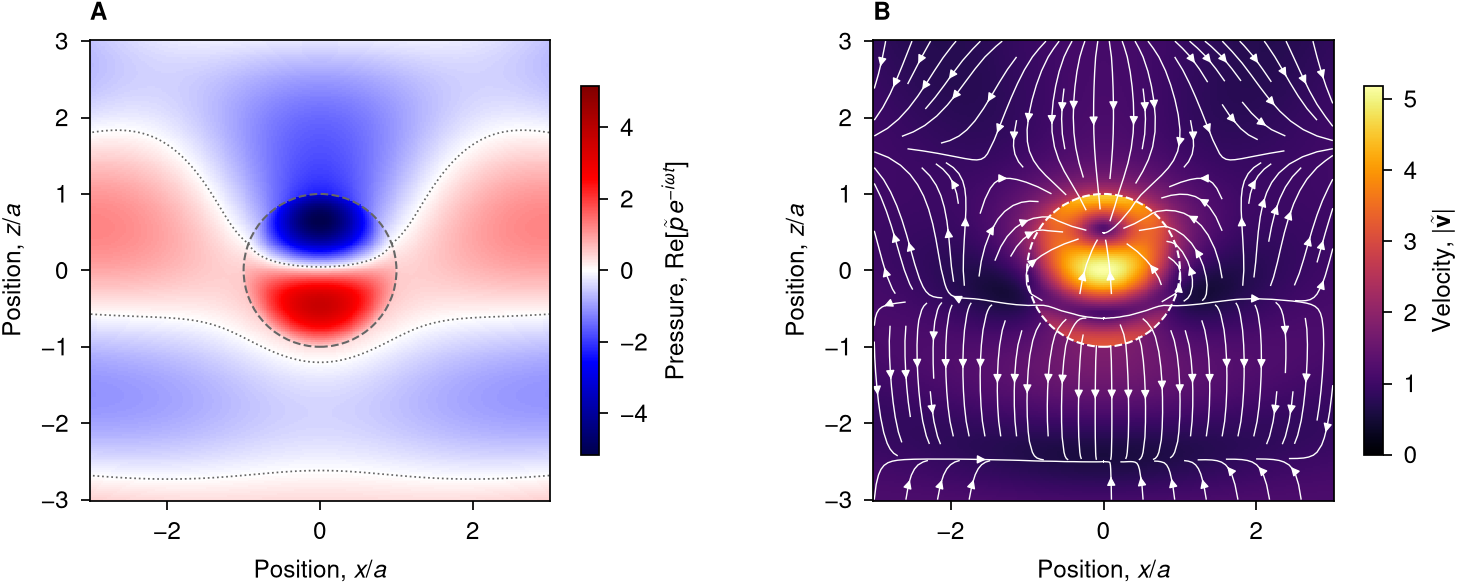

In [9]:
p, v = acoustic_fields(U, 0, V, ka, rho_rel, beta_rel, jmax)

fig, (ax1, ax2) = figure('double', cols=2)
mesh = signed_map(ax1, u, u, np.real(p * np.exp(-1j * wt)))
bar = fig.colorbar(mesh, ax=ax1, shrink=0.8, label=r'Pressure, $\mathrm{Re}[\tilde{p}\, e^{-i\omega t}]$')
bar.outline.set_linewidth(0.5)
vector_map(ax2, u, v, 0, wt, r'Velocity, $|\tilde{\mathbf{v}}|$')

for ax, color, name in zip([ax1, ax2], ['0.4', 'w'], 'AB'):
    ax.add_patch(plt.Circle((0, 0), 1, fill=False, color=color, ls='--', lw=0.6))
    ax.set_aspect('equal')
    ax.set_xlabel(r'Position, $x/a$')
    ax.set_ylabel(r'Position, $z/a$')
    letter(ax, name)

plt.show()